Goals:

- Update gene metadata
- Map annotation
- Do last-minute cell removal
- Tidy up .obs
- Write final object

In [23]:
from pathlib import Path
import os 
import tempfile
import shutil 

import pandas as pd
import scanpy as sc
from dotenv import dotenv_values
import matplotlib.pyplot as plt 

from hm3d_utils.utils import write_clean_h5ad
from project_utils import FileTracker

In [24]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])
ANNOT_DIR = DATADIR / "8_annotation"

ADATA_FP = DATADIR / "6_NC_projection" / "all_integrated" / "HypoMap3D_full.h5ad"
N_ANNOTATION_FP = ANNOT_DIR / "n_cluster_tree.csv"
NN_ANNOTATION_FP = ANNOT_DIR / "NN_annot_mapper.csv"

OUTDIR = DATADIR / "9_objects" 
OUTDIR_ADATA = OUTDIR / "singlecell"
os.makedirs(OUTDIR_ADATA, exist_ok=True)

CELL_HISTORY = DATADIR / "qc_log.csv" #QC log

tracker = FileTracker(log_file=DATADIR/'tracked_files.toml')

In [25]:
adata = sc.read_h5ad(ADATA_FP)

### Let's update the gene metadata

In [26]:
gene_metadata = adata.var.reset_index()

gene_metadata = gene_metadata.rename(columns={"index": "gene_name", })
further_exclude_mask = (
    gene_metadata["gene_name"].str.contains(r"Pde|Cntn|St18|C1q", regex=True, na=False)
    |
    gene_metadata["gene_name"].str.contains(r"\d+ot$", regex=True, na=False)
    |
    gene_metadata["gene_name"].str.contains(r"^[A-Z]{2}", regex=True, na=False)
)

gene_metadata.loc[further_exclude_mask, "IsAnnotationExcludedGene"] = True
gene_metadata.loc[further_exclude_mask, "IsPriorityGene"] = False
gene_metadata.loc[further_exclude_mask, "IsTopGene"] = False

furter_exclude_genes = gene_metadata.loc[further_exclude_mask, "gene_name"].to_list()

adata.var.loc[furter_exclude_genes, "IsAnnotationExcludedGene"] = True
adata.var.loc[furter_exclude_genes, "IsPriorityGene"] = False
adata.var.loc[furter_exclude_genes, "IsTopGene"] = False

In [27]:
# write final object
with tracker.register(OUTDIR / "gene_metadata.csv") as tf:
    tf.set_description('Final gene metadata')
    gene_metadata.to_csv(tf.filepath, index=False)

### Let's map the final annotations

In [28]:
adata

AnnData object with n_obs × n_vars = 1565227 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'L1', 'L2', 'L3', 'L4', 'L5', 'C66_named_propagated', 'C185_named_propagated', 'C286_named_propagated', 'C465_named_propagated', 'class_id_label_propagated', 'subclass_id_label_propagated', 'supertype_id_label_propagated', 'cluster_id_label_propagated', 'XistExpressing', 'UtyExpressing', 'sex_per_sample_inferred', 'xist_pct_per_sample', 'uty_pct_per_sample', 'L1_descr_v0.6', 'L2_descr_v0.6', 'L3_descr_v0.6', 'L4_descr_v0.6', 'L5_descr_v0.6', 'L2_prelim', 'L3_prelim', 'L4_prelim', 'L5_prelim'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanT

In [29]:
# rename columns to ID
adata.obs = adata.obs.rename(columns={
    f"L{i}": f"L{i}_ID" for i in range(1,6)
})
# fix name -> ID for L1_ID
adata.obs.L1_ID = adata.obs.L1_ID.apply(lambda x: x.split(" ")[0])

In [30]:
n_anno = pd.read_csv(N_ANNOTATION_FP)
nn_anno = pd.read_csv(NN_ANNOTATION_FP)

In [31]:
def build_id_mapping(n_df, nn_df, id_pattern, target_pattern, levels=range(1, 6),):
    mapping = {}

    # --- 1. from wide dataframe ---
    for i in levels:
        id_col = id_pattern.format(i=i)
        target_col = target_pattern.format(i=i)

        if id_col in n_df.columns and target_col in n_df.columns:
            mapping.update(
                n_df[[id_col, target_col]]
                .dropna()
                .drop_duplicates()
                .set_index(id_col)[target_col]
                .to_dict()
            )

    # --- 2. from nn_df (long format) ---
    if nn_df is not None:
        if not {"ID", "annot"}.issubset(nn_df.columns):
            raise ValueError("nn_df must contain columns ['ID', 'annot']")

        mapping.update(
            nn_df[["ID", "annot"]]
            .dropna()
            .drop_duplicates()
            .set_index("ID")["annot"]
            .to_dict()
        )

    return mapping

In [32]:
abclike_mapper = build_id_mapping(n_anno, nn_anno, 
    id_pattern="L{i}_ID",
    target_pattern="L{i}_abc_like")

descr_mapper = build_id_mapping(n_anno, nn_anno, 
    id_pattern="L{i}_ID",
    target_pattern="L{i}_descr")

In [33]:
for i in range(1,6):
    adata.obs[f"L{i}_abc_like"] = adata.obs[f"L{i}_ID"].map(abclike_mapper)
    adata.obs[f"L{i}_descr"] = adata.obs[f"L{i}_ID"].map(descr_mapper)
    assert adata.obs[f"L{i}_abc_like"].isna().sum() == 0, f"ABC-like at L{i} has nan"
    assert adata.obs[f"L{i}_descr"].isna().sum() == 0, f"Descr at L{i} has nan"

### Let's do a last-minute removal of low-quality Oligos

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


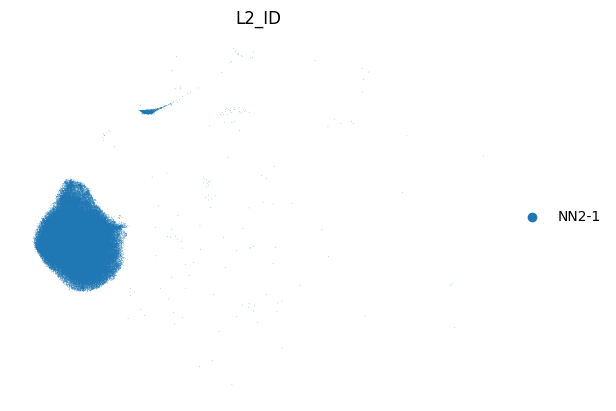

In [34]:
sc.pl.umap(adata[adata.obs.L2_ID=="NN2-1"], color="L2_ID", frameon=False)

In [35]:
remove_mask = (adata.obs.L2_ID=="NN2-1") & (adata.obsm["X_umap"][:, 1] > 7)

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


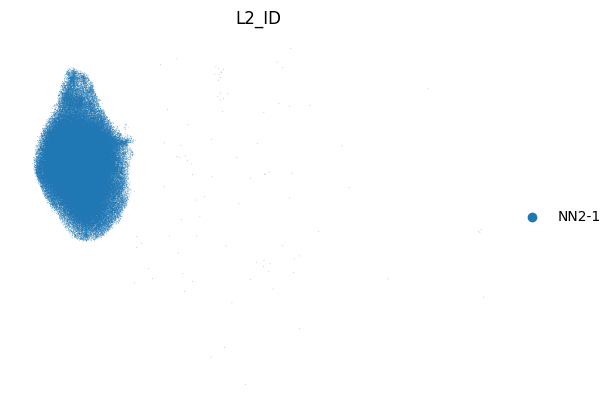

In [36]:
sc.pl.umap(adata[(adata.obs.L2_ID=="NN2-1") & (~remove_mask)], color="L2_ID", frameon=False)

In [37]:
remove_cells = list(adata.obs.loc[remove_mask].index)

In [38]:
adata = adata[~remove_mask].copy()

### Let's update the QC log 

In [39]:
# Load existing file
qc_log_df = pd.read_csv(CELL_HISTORY)

qc_log_df["IsLastMinuteRemoved"] = False
qc_log_df.loc[qc_log_df.CellID.isin(remove_cells), "IsLastMinuteRemoved"] = True

# Atomically replace cell history to avoid data corruption
output_path = CELL_HISTORY
output_dir = output_path.parent
# Create temp file in same directory
with tempfile.NamedTemporaryFile(mode="w", delete=False, dir=output_dir, suffix=".csv") as tmp:
    temp_path = Path(tmp.name)
    qc_log_df.to_csv(tmp.name, index=False)

os.replace(temp_path, output_path)

# write final object
with tracker.register(OUTDIR / "hypomap3d_singlecell_QC_log.csv") as tf:
    tf.set_description('Final QC log')
    qc_log_df.to_csv(tf.filepath, index=False)

### Let's tidy up .obs

Split obs into what is really necessary and save out the cluster labels from other atlases.

In [40]:
additional_columns = [
    'class_id_label', 'subclass_id_label', 'supertype_id_label', 'cluster_id_label', 
    'class_id_label_propagated', 'subclass_id_label_propagated', 'supertype_id_label_propagated', 'cluster_id_label_propagated',
    'C66_named', 'C185_named', 'C286_named', 'C465_named',
    'C66_named_propagated', 'C185_named_propagated', 'C286_named_propagated','C465_named_propagated', 
]

additional_obs = adata.obs.loc[:, ["CellID"] + additional_columns]

with tracker.register(OUTDIR_ADATA / "hypomap3d_singlecell_all_obs_extended.csv") as tf:
    tf.set_description('Extended .obs cell metadata: ABC and HMv1 labels: original and propagated')
    additional_obs.to_csv(tf.filepath, index=False)

In [41]:
keep_cols = [
    'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito',
    'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link',
    'Suspension', 'Technology', 
    'Author_Sex_harmonized', 'sex_per_sample_inferred', 
    'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl',
    'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 
    'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr',
    'L1_abc_like', 'L2_abc_like',  'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
]

In [42]:
adata.obs = adata.obs.loc[:, keep_cols]

In [43]:
adata

AnnData object with n_obs × n_vars = 1564064 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_umap'

In [44]:
with tracker.register(OUTDIR_ADATA / "hypomap3d_singlecell_all.h5ad") as tf:
    tf.set_description('Full Hypomap3D single cell object without spatial UMAP.')
    write_clean_h5ad(adata, tf.filepath)